# Building albedo

This notebook estimates the albedo of buildings in the Amsterdam street-view images, and shows how it varies over
the city. The albedo is estimated from the HSV value (V) of the building pixels:

1. Buildings are cut out of each image using the SAM3 `building` segmentation. Images where buildings cover
   less than 5% of the image are skipped.
2. The image is converted from sRGB to linear RGB, and V (the maximum of the R, G and B channels) is computed per
   pixel. Linear RGB is used as albedo is a ratio of light intensities, which the gamma-encoded sRGB values are not.
3. The albedo of an image is the mean V of its building pixels.
4. The albedo is aggregated on the grid of the facade fractions (`facade_fractions_with_confidence.nc`, also
   used for the emissivity map in `ams-emissivity.ipynb`), shown on a map, and written to a GeoTIFF file.

**Note:** V is only a rough proxy for albedo: it only covers visible light, and depends on the lighting (sun or
shade) and the camera.

The images and segmentations come from the `amsterdam-final` project (see `ams-map-workflow-confidence.ipynb` and
`ams-building-color.ipynb`).

In [1]:
from streetscapes.utils.db_access import get_image, get_segmentations, iter_segmentations, open_project

PROJECT = "amsterdam-final"

db = open_project(PROJECT, read_only=True)
# Limit the memory DuckDB uses (it defaults to 80% of the system memory). Reading the polygons column
# requires ~2 GB, as DuckDB decompresses it in large blocks.
_ = db.raw_sql("SET memory_limit = '4GB'")

In [2]:
# enter the run ID of the SAM3 segmentation run you want to use:
RUN_ID = "sam3-2026-09-18T11:01:36.418"

BUILDING_LABEL = "building"

# Minimum fraction of the image that has to be covered by buildings.
MIN_BUILDING_FRACTION = 0.05

# Number of randomly sampled images to process. Set to None to process all images.
N_IMAGES = None
SEED = 42

# The albedo is aggregated on the grid of the facade fractions file, so that it matches the emissivity map.
fractions_file = "facade_fractions_with_confidence.nc"
output_file = "building_albedo.tiff"

# not every cell has an albedo value. Missing values are replaced with the following:
NAN_ALBEDO = 0.15

# Number of images whose segmentations are loaded from the database in one query, and the number of
# threads that process the images of such a batch in parallel.
BATCH_SIZE = 100
N_WORKERS = 8

## Albedo per image

In [3]:
import numpy as np
import rasterio.features

from streetscapes.utils.image_processing import value_map


def building_polygons(segmentation):
    """The polygons of the building instances of a segmentation."""
    return [inst.polygon for inst in segmentation.instances if inst.label == BUILDING_LABEL]


def building_albedo(uuid, polygons):
    """Albedo (mean building V) of an image, given its building polygons.

    Returns (albedo, image, V, mask). albedo is None if the image has too few building pixels.
    """
    image = get_image(uuid)
    V = value_map(image)
    if polygons:
        mask = rasterio.features.rasterize(polygons, out_shape=V.shape, dtype=np.uint8) > 0
    else:
        mask = np.zeros(V.shape, dtype=bool)
    if mask.mean() <= MIN_BUILDING_FRACTION:
        return None, image, V, mask
    return V[mask].mean(), image, V, mask


def mean_building_albedo(uuid):
    """Same as building_albedo, but loads the segmentation of a single image."""
    segmentation = next(seg for seg in get_segmentations(uuid, project=PROJECT) if seg.id == RUN_ID)
    return building_albedo(uuid, building_polygons(segmentation))

A few examples of the cut out buildings and their V:

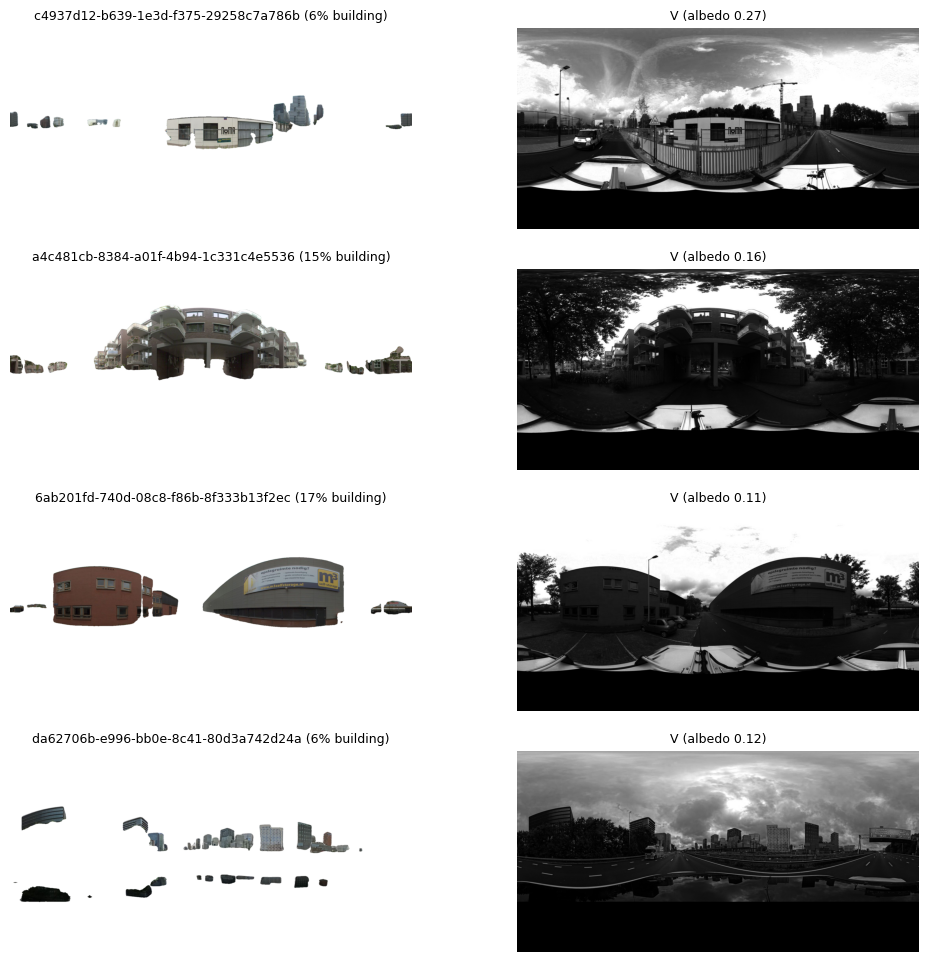

In [4]:
from matplotlib import pyplot as plt

images = db.table("images").uuid.to_pandas().astype(str)
rng = np.random.default_rng(SEED)
subset = images if N_IMAGES is None else images.iloc[rng.choice(len(images), N_IMAGES, replace=False)]

examples = []
for uuid in subset:
    albedo, image, V, mask = mean_building_albedo(uuid)
    if albedo is not None:
        examples.append((uuid, albedo, image, V, mask))
    if len(examples) == 4:
        break

fig, axes = plt.subplots(nrows=len(examples), ncols=2, figsize=(12, 3 * len(examples)))
for (uuid, albedo, image, V, mask), (ax_img, ax_v) in zip(examples, axes):
    cutout = np.asarray(image).copy()
    cutout[~mask] = 255
    ax_img.imshow(cutout)
    ax_img.set_title(f"{uuid} ({mask.mean():.0%} building)", fontsize=9)
    ax_v.imshow(V, cmap="gray", vmin=0, vmax=1)
    ax_v.set_title(f"V (albedo {albedo:.2f})", fontsize=9)
    for ax in (ax_img, ax_v):
        ax.axis("off")

Now compute the albedo for all images in the subset. See `ams-building-color.ipynb` for how the images are
processed in parallel:

In [5]:
import math
from concurrent.futures import ThreadPoolExecutor
from IPython.display import clear_output

import geopandas
from tqdm import tqdm

m = db.table("mapillary")
locations = (
    m.filter(m.image.isin(subset.tolist()))
    .select("image", "geometry")
    .to_pandas()
    .assign(image=lambda df: df["image"].astype(str))
    .drop_duplicates("image")
    .set_index("image")["geometry"]
)


def process_image(uuid, segmentation):
    """Returns a record for the image, or None if it has no location or too few building pixels."""
    if uuid not in locations.index:
        return None
    albedo, _, _, mask = building_albedo(uuid, building_polygons(segmentation))
    if albedo is None:
        return None
    return {
        "image": uuid,
        "albedo": albedo,
        "building_fraction": mask.mean(),
        "geometry": locations[uuid],
    }


records = []
batches = iter_segmentations(RUN_ID, subset.tolist(), batch_size=BATCH_SIZE, project=PROJECT, con=db)

with ThreadPoolExecutor(N_WORKERS) as pool:
    for batch in tqdm(batches, total=math.ceil(len(subset) / BATCH_SIZE)):
        results = pool.map(lambda item: process_image(*item), batch.items())
        records += [record for record in results if record is not None]
clear_output()  # clear progress bar for nicer saved notebook

albedos = geopandas.GeoDataFrame(records, crs="EPSG:4326")
print(f"{len(albedos)} of {len(subset)} images have more than {MIN_BUILDING_FRACTION:.0%} building pixels")
albedos.head()

12147 of 19956 images have more than 5% building pixels


,image,albedo,building_fraction,geometry
0,c4937d12-b639-1e3d-f375-29258c7a786b,0.273726,0.056817,POINT (4.86712 52.33671)
1,a4c481cb-8384-a01f-4b94-1c331c4e5536,0.159863,0.146101,POINT (4.86715 52.37419)
2,6ab201fd-740d-08c8-f86b-8f333b13f2ec,0.110134,0.174136,POINT (4.86729 52.3821)
3,da62706b-e996-bb0e-8c41-80d3a742d24a,0.123792,0.059222,POINT (4.86772 52.33937)
4,bdb7ab3a-c8f7-ac26-45f8-b2ab2a5ab063,0.151110,0.122865,POINT (4.86771 52.35575)


## Albedo on the map

Aggregate the albedo on the grid of the facade fractions. The albedo of a grid cell is the mean of all images in
that cell. The histogram shows the albedo of all individual images:

Text(0.5, 1.0, 'Building albedo per image')

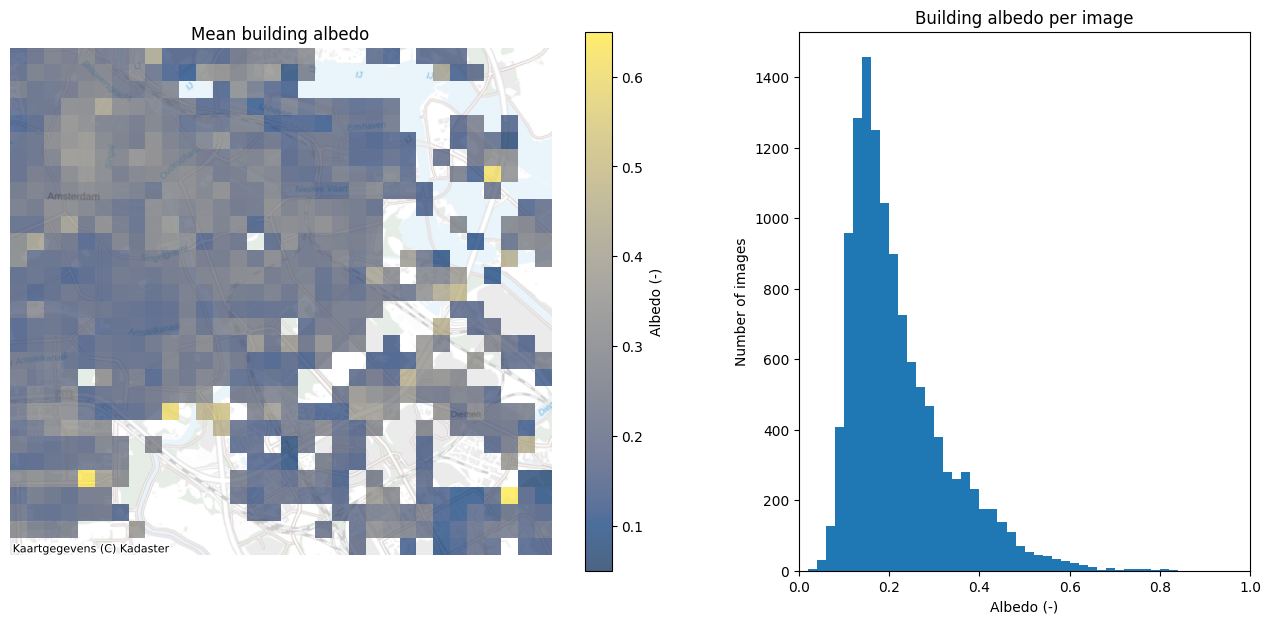

In [6]:
import contextily
import rasterio
import rasterio.plot
import xarray as xr
from rasterio.transform import Affine

ds = xr.open_dataset(fractions_file)
crs = rasterio.CRS.from_wkt(ds["spatial_ref"].attrs["crs_wkt"])
transform = Affine.from_gdal(*map(float, ds["spatial_ref"].attrs["GeoTransform"].split()))

albedos_proj = albedos.to_crs(crs)
cell_col, cell_row = ~transform * (albedos_proj.geometry.x.to_numpy(), albedos_proj.geometry.y.to_numpy())
cells = albedos_proj.assign(row=np.floor(cell_row).astype(int), col=np.floor(cell_col).astype(int))
cells = cells[cells["row"].between(0, ds.sizes["y"] - 1) & cells["col"].between(0, ds.sizes["x"] - 1)]
cell_means = cells.groupby(["row", "col"])["albedo"].mean()

albedo = xr.full_like(ds["brick_fraction"], np.nan).rename("albedo")
albedo.values[cell_means.index.get_level_values("row"), cell_means.index.get_level_values("col")] = cell_means.to_numpy()
albedo.attrs = {"long_name": "Building albedo", "units": "-", "grid_mapping": "spatial_ref"}

fig, (ax_map, ax_hist) = plt.subplots(ncols=2, figsize=(16, 7), width_ratios=[3, 2])

extent = rasterio.plot.plotting_extent(albedo.to_numpy(), transform)
albedo_image = ax_map.imshow(albedo, extent=extent, cmap="cividis", alpha=0.7, vmin=0.05, vmax=0.65, interpolation="nearest", zorder=2)
contextily.add_basemap(ax_map, crs=crs, source=contextily.providers.nlmaps.grijs)
fig.colorbar(albedo_image, ax=ax_map, label="Albedo (-)")
ax_map.set_title("Mean building albedo")
ax_map.axis("off")

ax_hist.hist(albedos["albedo"], bins=np.linspace(0, 1, 51))
ax_hist.set_xlim(0, 1)
ax_hist.set_xlabel("Albedo (-)")
ax_hist.set_ylabel("Number of images")
ax_hist.set_title("Building albedo per image")

Write the albedo to a GeoTIFF file, with the same CRS and geotransform as the facade fractions file. Cells without
any images are filled with `NAN_ALBEDO`:

In [7]:
no_nan_albedo = xr.where(albedo.isnull(), NAN_ALBEDO, albedo)

with rasterio.open(
    output_file,
    "w",
    driver="GTiff",
    height=albedo.sizes["y"],
    width=albedo.sizes["x"],
    count=1,
    dtype="float32",
    crs=crs,
    transform=transform,
    nodata=np.nan,
) as dst:
    dst.write(no_nan_albedo.to_numpy().astype("float32"), 1)
    dst.set_band_description(1, "building albedo")
    dst.update_tags(1, units="-", nan_albedo=str(NAN_ALBEDO))

Read the GeoTIFF back in and plot it on a map:

{'driver': 'GTiff', 'dtype': 'float32', 'nodata': nan, 'width': 32, 'height': 30, 'count': 1, 'crs': CRS.from_wkt('PROJCS["Amersfoort / RD New",GEOGCS["Amersfoort",DATUM["Amersfoort",SPHEROID["Bessel 1841",6377397.155,299.1528128,AUTHORITY["EPSG","7004"]],AUTHORITY["EPSG","6289"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4289"]],PROJECTION["Oblique_Stereographic"],PARAMETER["latitude_of_origin",52.1561605555556],PARAMETER["central_meridian",5.38763888888889],PARAMETER["scale_factor",0.9999079],PARAMETER["false_easting",155000],PARAMETER["false_northing",463000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","28992"]]'), 'transform': Affine(250.0, 0.0, 119540.70360773578,
       0.0, -250.0, 488793.76151340216), 'blockxsize': 32, 'blockysize': 30, 'tiled': False, 'interleave': 'band'}


(np.float64(119540.70360773578),
 np.float64(127540.70360773578),
 np.float64(481293.76151340216),
 np.float64(488793.76151340216))

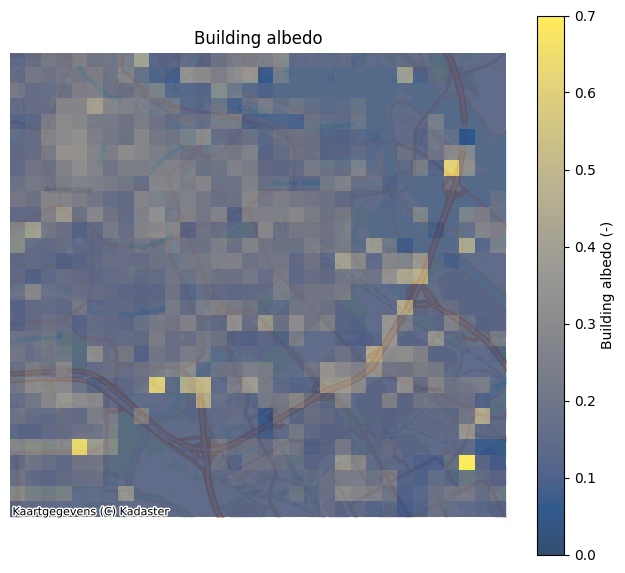

In [ ]:
with rasterio.open(output_file) as src:
    print(src.profile)
    data = src.read(1)
    raster_extent = rasterio.plot.plotting_extent(src)
    raster_crs = src.crs

fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(data, extent=raster_extent, cmap="cividis", vmin= 0, vmax=0.7, alpha=0.8, zorder=2)
contextily.add_basemap(ax, crs=raster_crs, source=contextily.providers.nlmaps.pastel)
fig.colorbar(image, ax=ax, label="Building albedo (-)")
ax.set_title("Building albedo")
ax.axis("off")